In [1]:
%pip install -q datasets pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
from datasets import load_dataset

dataset = load_dataset(
    "pminervini/HaluEval",
    "qa",
    split="data"
)

print("Number of dataset rows:", len(dataset))
print("Columns:", dataset.column_names)
print("First example:")
print(dataset[0])

README.md:   0%|          | 0.00/2.88k [00:00<?, ?B/s]

qa/data-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.75MB            

qa/data-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating data split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Number of dataset rows: 10000
Columns: ['knowledge', 'question', 'right_answer', 'hallucinated_answer']
First example:
{'knowledge': "Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.First for Women is a woman's magazine published by Bauer Media Group in the USA.", 'question': "Which magazine was started first Arthur's Magazine or First for Women?", 'right_answer': "Arthur's Magazine", 'hallucinated_answer': 'First for Women was started first.'}


In [3]:
import pandas as pd

df = dataset.to_pandas()

required_columns = [
    "knowledge",
    "question",
    "right_answer",
    "hallucinated_answer"
]

df = df[required_columns].dropna().copy()

print("Dataset shape:", df.shape)
display(df.head(5))

Dataset shape: (10000, 4)


,knowledge,question,right_answer,hallucinated_answer
0,Arthur's Magazine (1844–1846) was an American ...,Which magazine was started first Arthur's Maga...,Arthur's Magazine,First for Women was started first.
1,The Oberoi family is an Indian family that is ...,The Oberoi family is part of a hotel company t...,Delhi,The Oberoi family's hotel company is based in ...
2,"Allison Beth ""Allie"" Goertz (born March 2, 199...",Musician and satirist Allie Goertz wrote a son...,President Richard Nixon,"Allie Goertz wrote a song about Milhouse, a po..."
3,"Margaret ""Peggy"" Seeger (born June 17, 1935) i...",What nationality was James Henry Miller's wife?,American,James Henry Miller's wife was British.
4,It is a hygroscopic solid that is highly solu...,Cadmium Chloride is slightly soluble in this c...,alcohol,water with a hint of alcohol


In [4]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

print("Training question pairs:", len(train_df))
print("Testing question pairs:", len(test_df))

Training question pairs: 8000
Testing question pairs: 2000


In [5]:
def make_examples(data):
    examples = []

    for _, row in data.iterrows():
        context = (
            "Knowledge: " + str(row["knowledge"]) +
            "\nQuestion: " + str(row["question"])
        )

        # Correct answer: label 0
        examples.append({
            "text": context + "\nAnswer: " + str(row["right_answer"]),
            "label": 0
        })

        # Hallucinated answer: label 1
        examples.append({
            "text": context + "\nAnswer: " + str(row["hallucinated_answer"]),
            "label": 1
        })

    return pd.DataFrame(examples)

train_examples = make_examples(train_df)
test_examples = make_examples(test_df)

X_train = train_examples["text"]
y_train = train_examples["label"]

X_test = test_examples["text"]
y_test = test_examples["label"]

print("Training examples:", len(train_examples))
print("Testing examples:", len(test_examples))
print("\nExample training record:")
print(train_examples.iloc[0]["text"])
print("Label:", train_examples.iloc[0]["label"])

Training examples: 16000
Testing examples: 4000

Example training record:
Knowledge: Vincenzo Salvatore Carmelo Francesco Bellini (] ; 3 November 1801 – 23 September 1835) was an Italian opera composer, who was known for his long-flowing melodic lines for which he was named "the Swan of Catania".Igor Fyodorovich Stravinsky (sometimes spelled "Strawinski", "Strawinsky", or "Stravinskii"; Ukrainian: І́гор Фе́дорович Страві́нський , ] ;Russian: И́горь Фёдорович Страви́нский , "Igorʹ Fëdorovič Stravinskij"; ] ; 17 June [O.S. 5 June] 1882 6 April 1971) was a Russian Empire-born composer, pianist, and conductor.
Question: Who has knowledge of more arts, Vincenzo Bellini or Igor Stravinsky
Answer: Igor Fyodorovich Stravinsky
Label: 0


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            stop_words="english",
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

model.fit(X_train, y_train)

print("Training completed successfully!")

Training completed successfully!


In [7]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not hallucinated", "Hallucinated"],
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.599

Classification report:
                  precision    recall  f1-score   support

Not hallucinated       0.58      0.69      0.63      2000
    Hallucinated       0.62      0.51      0.56      2000

        accuracy                           0.60      4000
       macro avg       0.60      0.60      0.60      4000
    weighted avg       0.60      0.60      0.60      4000

Confusion matrix:
[[1381  619]
 [ 985 1015]]


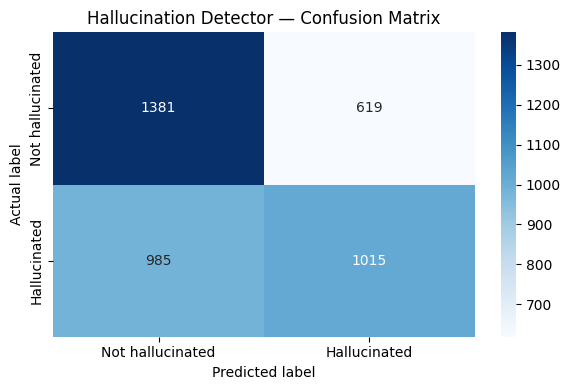

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not hallucinated", "Hallucinated"],
    yticklabels=["Not hallucinated", "Hallucinated"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Hallucination Detector — Confusion Matrix")
plt.tight_layout()
plt.show()

In [9]:
import joblib
from pathlib import Path

output_dir = Path("/content/hallucination_detector")
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / "hallucination_model.joblib"

joblib.dump(model, model_path)

print("Model saved to:", model_path)

Model saved to: /content/hallucination_detector/hallucination_model.joblib


In [10]:
def predict_hallucination(knowledge, question, answer):
    text = (
        f"Knowledge: {knowledge}\n"
        f"Question: {question}\n"
        f"Answer: {answer}"
    )

    prediction = int(model.predict([text])[0])
    probabilities = model.predict_proba([text])[0]

    result = (
        "Hallucinated"
        if prediction == 1
        else "Not hallucinated"
    )

    print("Prediction:", result)
    print(
        "Estimated hallucination probability:",
        f"{probabilities[1]:.2%}"
    )

    return {
        "prediction": result,
        "hallucination_probability": float(probabilities[1])
    }


result = predict_hallucination(
    knowledge="Paris is the capital of France.",
    question="What is the capital of France?",
    answer="Paris is the capital of France."
)

Prediction: Not hallucinated
Estimated hallucination probability: 44.15%


In [11]:
result = predict_hallucination(
    knowledge="Paris is the capital of France.",
    question="What is the capital of France?",
    answer="Lyon is the capital of France."
)

Prediction: Not hallucinated
Estimated hallucination probability: 42.94%


In [12]:
from google.colab import files

files.download(
    "/content/hallucination_detector/hallucination_model.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>